In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

In [3]:
f_mnist = keras.datasets.fashion_mnist

In [4]:
(X_train_full, y_train_full), (X_test, y_test) = f_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step 
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
X_train_full.shape,y_train_full.shape,X_test.shape,y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

In [6]:
X_valid, X_train = X_train_full[:5000] / 255.0, X_train_full[5000:] / 255.0
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]

In [7]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [8]:
model = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[28,28]),
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

/Users/prakashchaudhary/Documents/Documentation ML/tensorflow_project/tensorflow-env/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [12]:
hidden1 = model.layers[1]
hidden1.name

'dense'

In [13]:
model.get_layer('dense') is hidden1

True

In [15]:
weights, biases = hidden1.get_weights()
weights, biases

(array([[-0.01361872, -0.01282591,  0.06662227, ...,  0.03016695,
         -0.05571495, -0.03530172],
        [ 0.07308032,  0.02631442,  0.01560929, ..., -0.01566105,
         -0.06204806, -0.0631628 ],
        [ 0.04666889,  0.05702655,  0.03450843, ...,  0.04374423,
         -0.03436952,  0.01776157],
        ...,
        [-0.0715012 , -0.00595827, -0.05990244, ..., -0.06271536,
          0.03416676, -0.01593427],
        [-0.02053785, -0.06520877,  0.03446   , ..., -0.03078504,
          0.05680428,  0.05367793],
        [ 0.04762486, -0.04297774,  0.01048604, ...,  0.0348143 ,
         -0.00962947,  0.02256464]], shape=(784, 300), dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 

In [16]:
weights.shape, biases.shape

((784, 300), (300,))

In [17]:
model.compile(loss="sparse_categorical_crossentropy",
             optimizer="sgd",
             metrics=["accuracy"]
)

In [18]:
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 660us/step - accuracy: 0.7653 - loss: 0.7181 - val_accuracy: 0.8328 - val_loss: 0.5038
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 573us/step - accuracy: 0.8281 - loss: 0.4941 - val_accuracy: 0.8466 - val_loss: 0.4545
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 618us/step - accuracy: 0.8431 - loss: 0.4466 - val_accuracy: 0.8620 - val_loss: 0.4194
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 610us/step - accuracy: 0.8529 - loss: 0.4169 - val_accuracy: 0.8576 - val_loss: 0.4159
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 573us/step - accuracy: 0.8605 - loss: 0.3967 - val_accuracy: 0.8566 - val_loss: 0.4117
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 583us/step - accuracy: 0.8663 - loss: 0.3798 - val_accuracy: 0.8686 - val_loss: 0.3823
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 598us/step - accuracy: 0.8714 - loss: 0.3662 - val_accuracy: 0.8770 - val_loss: 0.3628
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 611us/step - accuracy: 0.8756 -

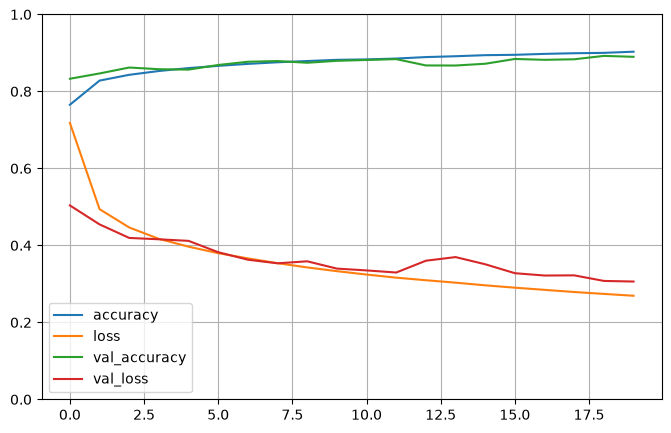

In [19]:
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0, 1) # set the vertical range to (0-1)
plt.show()

In [20]:
model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step - accuracy: 0.8478 - loss: 60.2230


[60.22303009033203, 0.8478000164031982]

In [21]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [22]:
y_pred = model.predict(X_new).argmax(axis=1)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


array([9, 2, 1])

In [23]:
np.array(class_names)[y_pred]

array(['Ankle boot', 'Pullover', 'Trouser'], dtype='<U11')

In [24]:
y_new = y_test[:3]
y_new

array([9, 2, 1], dtype=uint8)